# Redes Neurais Artificiais — Projeto Prático 2.1

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- João Victor Mattos Lopes (github.com/Jaum36) - 2315080034
- Gabriel Augusto da Eira Corrêa Benayon (github.com/devgabrielbenayon) - 2415310049

Identificador dos exemplos: (4 + 9) % 4 = 1. 

In [5]:
# Numpy obrigatório para manipulação de arrays e matrizes
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
import prettytable as pt

from sklearn.metrics import (
  ConfusionMatrixDisplay,
  accuracy_score,
  precision_score,
  recall_score,
  f1_score
)


In [6]:
identificador = (4 + 9) % 4

dados = np.load(f"data/data{identificador}20262.txt").reshape(-1, 3)
X = dados[:, :2]
y = dados[:, 2]

# Parte I - Resolvendo um Problema Linearmente Separável

In [7]:
class Perceptron:
  def __init__(self, taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5)):
    self.taxa_aprendizado = taxa_aprendizado
    self.intervalo_pesos = intervalo_pesos
    self.w = None  # [viés, w1, w2]

  def _adicionar_bias(self, X):
    return np.hstack((np.ones((X.shape[0], 1)), X))

  def _degrau(self, u):
    return np.where(u >= 0, 1, 0)

  def train(self, X, y, max_epocas=None, embaralhar=False, verbose=True):
    Xb = self._adicionar_bias(X)
    self.w = np.random.uniform(self.intervalo_pesos[0], self.intervalo_pesos[1], Xb.shape[1])

    if verbose:
      print(f"Vetor inicial de pesos [viés, w1, w2]: {self.w}")

    epocas = 0
    ajustes = 0

    # Sem max_epocas, treina até a convergência
    while max_epocas is None or epocas < max_epocas:
      epocas += 1
      erros = 0

      indices = np.random.permutation(len(Xb)) if embaralhar else np.arange(len(Xb))

      for i in indices:
        erro = y[i] - self._degrau(np.dot(self.w, Xb[i]))

        if erro != 0:
          self.w = self.w + self.taxa_aprendizado * erro * Xb[i]
          erros += 1
          ajustes += 1

      if erros == 0:
        break

    if verbose:
      print(f"Número total de ajustes no vetor de pesos: {ajustes}")
      print(f"Número de épocas até a convergência: {epocas}")

    return epocas, ajustes

  def predict(self, X):
    return self._degrau(np.dot(self._adicionar_bias(X), self.w))


In [8]:
dados = np.load("data/dataAll20262.txt").reshape(-1, 3)
entradas = dados[:, :2]
saida = dados[:, 2]

p = Perceptron(taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5))

epocas, ajustes = p.train(entradas, saida)

Vetor inicial de pesos [viés, w1, w2]: [ 0.1788498  -0.16769305 -0.21256887]
Número total de ajustes no vetor de pesos: 65
Número de épocas até a convergência: 4


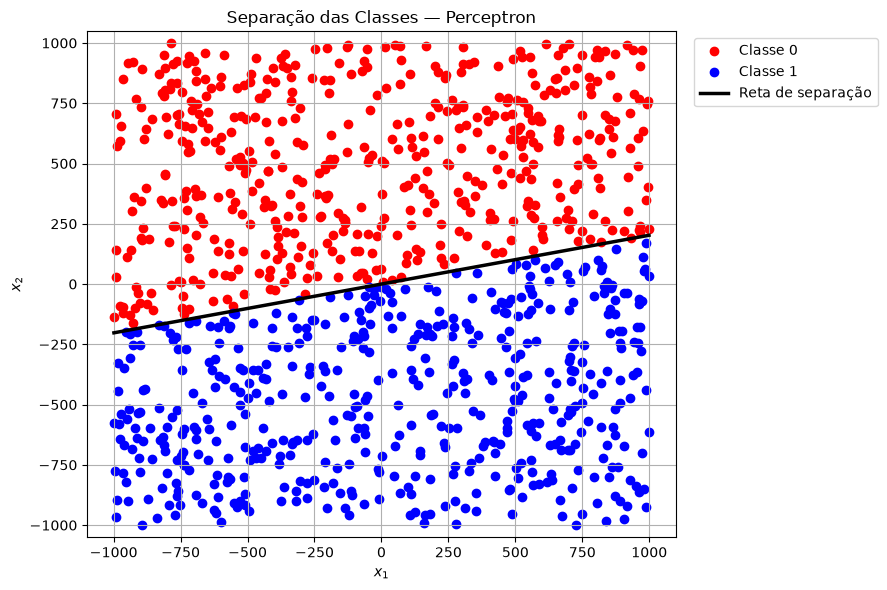

In [9]:
classe_0 = saida == 0
classe_1 = saida == 1

vies, w1, w2 = p.w

plt.figure(figsize=(9, 6))
plt.scatter(entradas[classe_0, 0], entradas[classe_0, 1], c='red', label="Classe 0")
plt.scatter(entradas[classe_1, 0], entradas[classe_1, 1], c='blue', label="Classe 1")

# Reta de separação: vies + w1*x1 + w2*x2 = 0
if w2 != 0:
  x1_reta = np.linspace(entradas[:, 0].min(), entradas[:, 0].max(), 200)
  x2_reta = -(w1 * x1_reta + vies) / w2
  plt.plot(x1_reta, x2_reta, color="black", linewidth=2.5, label="Reta de separação")
else:
  plt.axvline(-vies / w1, color="black", linewidth=2.5, label="Reta de separação")

plt.ylim(entradas[:, 1].min() - 50, entradas[:, 1].max() + 50)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Separação das Classes — Perceptron")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# Parte II - Experimentação

Arquivo `data120262.txt` (identificador 1). O algoritmo da Parte I é executado 10 vezes para cada uma das 6 configurações de taxa de aprendizado η ∈ {0.4, 0.1, 0.01} e intervalo de inicialização dos pesos I ∈ {(−100, +100), (−0.5, +0.5)}.

In [10]:
taxas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
repeticoes = 10

np.random.seed(identificador)

resultados = []

for taxa in taxas:
  for intervalo in intervalos:
    epocas_exec = np.zeros(repeticoes, dtype=int)
    ajustes_exec = np.zeros(repeticoes, dtype=int)

    for r in range(repeticoes):
      p2 = Perceptron(taxa_aprendizado=taxa, intervalo_pesos=intervalo)
      epocas_exec[r], ajustes_exec[r] = p2.train(X, y, verbose=False)

    resultados.append({
      "taxa": taxa,
      "intervalo_str": f"({intervalo[0]:+g}, {intervalo[1]:+g})",
      "epocas": epocas_exec,
      "ajustes": ajustes_exec,
    })
    print(f"η = {taxa}, I = {intervalo}: concluído")

η = 0.4, I = (-100, 100): concluído
η = 0.4, I = (-0.5, 0.5): concluído
η = 0.1, I = (-100, 100): concluído
η = 0.1, I = (-0.5, 0.5): concluído
η = 0.01, I = (-100, 100): concluído
η = 0.01, I = (-0.5, 0.5): concluído


In [11]:
tabela = pt.PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for r in resultados:
  tabela.add_row([
    f"η = {r['taxa']}",
    r["intervalo_str"],
    f"{r['ajustes'].mean():.2f} ± {r['ajustes'].std(ddof=1):.2f}",
    r["epocas"].min(),
    r["epocas"].max(),
  ])

print(tabela)

+---------------------+--------------------+-----------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |      Qtde Ajustes     | Min Épocas | Max Épocas |
+---------------------+--------------------+-----------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    | 317381.40 ± 132267.77 |    835     |    5169    |
|       η = 0.4       |    (-0.5, +0.5)    |  270723.30 ± 83558.92 |    1511    |    3643    |
|       η = 0.1       |    (-100, +100)    |  274658.70 ± 93979.51 |    1507    |    4581    |
|       η = 0.1       |    (-0.5, +0.5)    |  247757.80 ± 75504.20 |    737     |    2830    |
|       η = 0.01      |    (-100, +100)    | 360335.10 ± 140100.06 |    1683    |    6995    |
|       η = 0.01      |    (-0.5, +0.5)    | 294322.70 ± 136186.65 |    1486    |    7053    |
+---------------------+--------------------+-----------------------+------------+------------+


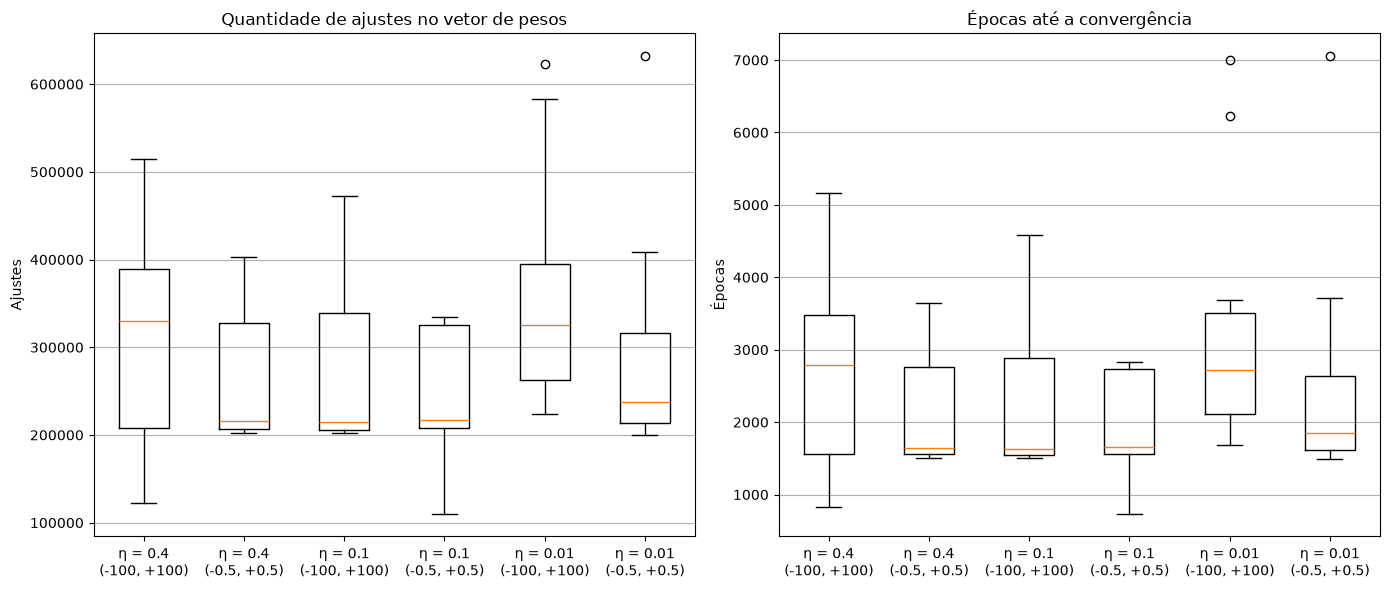

In [12]:
rotulos = [f"η = {r['taxa']}\n{r['intervalo_str']}" for r in resultados]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.boxplot([r["ajustes"] for r in resultados], tick_labels=rotulos)
ax1.set_title("Quantidade de ajustes no vetor de pesos")
ax1.set_ylabel("Ajustes")
ax1.grid(True, axis="y")

ax2.boxplot([r["epocas"] for r in resultados], tick_labels=rotulos)
ax2.set_title("Épocas até a convergência")
ax2.set_ylabel("Épocas")
ax2.grid(True, axis="y")

plt.tight_layout()
plt.show()

### Análise dos resultados

Nas dez execuções de cada configuração, houve bastante variação na quantidade de ajustes e no número de épocas até a convergência. A configuração com taxa de aprendizado de 0,1 e pesos iniciais entre −0,5 e +0,5 teve a menor média de ajustes, cerca de 248 mil. A maior média foi de aproximadamente 360 mil, com taxa de 0,01 e pesos entre −100 e +100. Porém, os desvios padrão foram elevados, entre cerca de 76 mil e 140 mil ajustes.

Os boxplots mostram sobreposição entre os resultados das configurações. Isso, junto da variação observada nas execuções, não permite apontar com segurança uma configuração superior às demais. Também não podemos afirmar que elas sejam equivalentes apenas com essa comparação.

Ao comparar os dois intervalos de inicialização, as médias de ajustes foram menores com pesos entre −0,5 e +0,5 nas três taxas testadas. Já a redução da taxa de aprendizado não foi acompanhada por uma redução contínua na média de ajustes. A taxa de 0,1 teve a menor média nos dois intervalos, mas seriam necessárias mais execuções e uma análise estatística para avaliar se essas diferenças se mantêm.

O treinamento levou milhares de épocas em várias execuções. Uma possível explicação está na escala das entradas: enquanto a atualização do viés é proporcional a η, a dos outros pesos depende também dos valores de cada entrada. Essa diferença pode influenciar o tempo até a convergência, mas seria necessário realizar outros experimentos para verificar sua contribuição neste conjunto de dados.

# Parte III - Validação Holdout em Problema Não-Linearmente Separável

Arquivo `dataHoldout20262.txt`. Os exemplos são divididos aleatoriamente em 70% para treinamento e 30% para teste, com semente igual ao identificador da equipe (1). O Perceptron usa função degrau com ϑ = 0, η = 0,1 (valor usual na literatura, com 0 < η ≤ 1) e pesos iniciais em U(−0,5, +0,5), e é treinado por 100 épocas, com os exemplos apresentados em ordem aleatória a cada época.

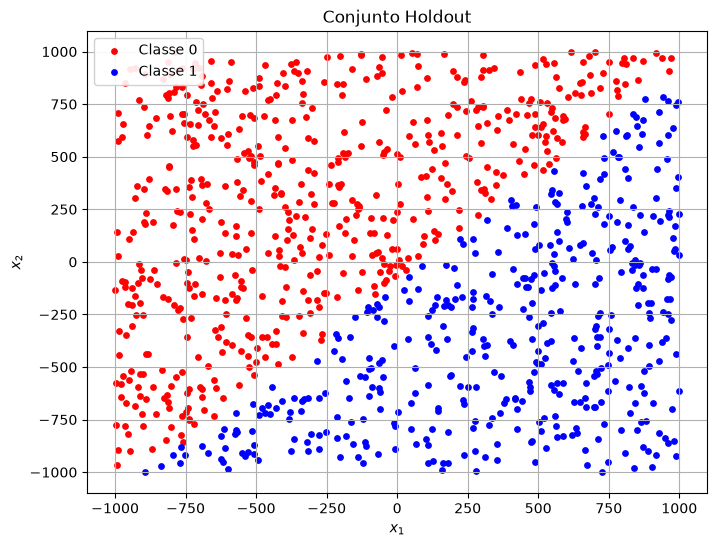

In [13]:
dados_holdout = np.load("data/dataHoldout20262.txt").reshape(-1, 3)
X_holdout = dados_holdout[:, :2]
y_holdout = dados_holdout[:, 2]

def plotar_dados(ax, X, y, titulo, w=None):
  ax.scatter(X[y == 0, 0], X[y == 0, 1], c='red', s=15, label="Classe 0")
  ax.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', s=15, label="Classe 1")

  # Reta de separação: vies + w1*x1 + w2*x2 = 0
  if w is not None:
    vies, w1, w2 = w
    limites_y = ax.get_ylim()
    x1_reta = np.linspace(*ax.get_xlim(), 200)
    ax.plot(x1_reta, -(w1 * x1_reta + vies) / w2, color="black", linewidth=2.5, label="Reta de separação")
    ax.set_ylim(limites_y)

  ax.set_xlabel("$x_1$")
  ax.set_ylabel("$x_2$")
  ax.set_title(titulo)
  ax.legend(loc="upper left", framealpha=0.9)
  ax.grid(True)

fig, ax = plt.subplots(figsize=(8, 6))
plotar_dados(ax, X_holdout, y_holdout, "Conjunto Holdout")
plt.show()

O gráfico evidencia que o problema **não é linearmente separável**: a classe 0 (vermelho) ocupa a região superior esquerda e a classe 1 (azul) a inferior direita, mas a fronteira entre elas é curva. Na parte inferior esquerda, por exemplo, exemplos azuis avançam para a região vermelha. Qualquer reta que acompanhe a fronteira na parte central deixa exemplos do lado errado nas extremidades, portanto nenhuma reta separa todos os exemplos.

In [14]:
np.random.seed(identificador)

indices = np.random.permutation(len(X_holdout))
n_treino = int(0.7 * len(X_holdout))

X_treino, y_treino = X_holdout[indices[:n_treino]], y_holdout[indices[:n_treino]]
X_teste, y_teste = X_holdout[indices[n_treino:]], y_holdout[indices[n_treino:]]

print(f"Treinamento: {len(X_treino)} exemplos | Teste: {len(X_teste)} exemplos")

Treinamento: 700 exemplos | Teste: 300 exemplos


In [15]:
p3 = Perceptron(taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5))

epocas3, ajustes3 = p3.train(X_treino, y_treino, max_epocas=100, embaralhar=True, verbose=False)

print(f"Épocas executadas: {epocas3}")
print(f"Número total de ajustes no vetor de pesos: {ajustes3}")
print(f"Vetor final de pesos [viés, w1, w2]: {p3.w}")

Épocas executadas: 100
Número total de ajustes no vetor de pesos: 4685
Vetor final de pesos [viés, w1, w2]: [-411.65430118  387.28086332 -438.44061858]


In [16]:
y_pred_treino = p3.predict(X_treino)

acuracia_treino = accuracy_score(y_treino, y_pred_treino)
print(f"Acurácia no treinamento: {acuracia_treino:.2%}")

Acurácia no treinamento: 94.57%


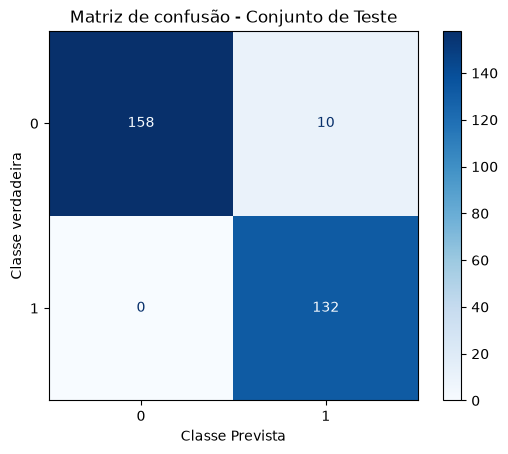

In [17]:
y_pred = p3.predict(X_teste)

matriz = ConfusionMatrixDisplay.from_predictions(y_teste, y_pred, display_labels=[0,1], cmap="Blues")

plt.title("Matriz de confusão - Conjunto de Teste")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe verdadeira")
plt.show()

In [18]:
acuracia = accuracy_score(y_teste, y_pred)
precisao = precision_score(y_teste, y_pred, pos_label=1)
revocacao = recall_score(y_teste, y_pred, pos_label=1)
f1 = f1_score(y_teste, y_pred, pos_label=1)

print(f"Acurácia = {acuracia:.2%}")
print(f"Precisão = {precisao:.2%}")
print(f"Revocação = {revocacao:.2%}")
print(f"F1-score = {f1:.2%}")

Acurácia = 96.67%
Precisão = 92.96%
Revocação = 100.00%
F1-score = 96.35%


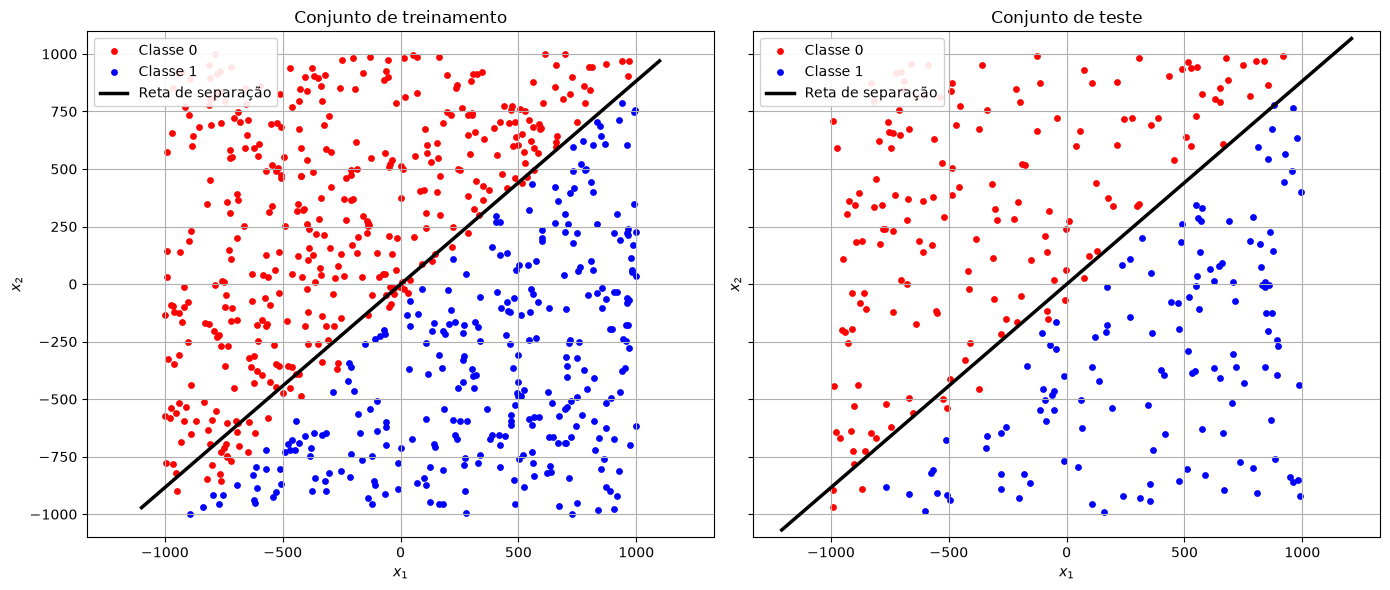

In [19]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

plotar_dados(
    ax1, X_treino, y_treino,
    "Conjunto de treinamento",
    w=p3.w
)

plotar_dados(
    ax2, X_teste, y_teste,
    "Conjunto de teste",
    w=p3.w
)

plt.tight_layout()
plt.show()

## Resposta referente a questão 4. da Parte III:
O Perceptron acertou 96,67% dos exemplos do conjunto de teste. A revocação de 100% mostra que todos os exemplos da classe 1 foram identificados corretamente. Os erros ocorreram em exemplos da classe 0 que foram classificados como 1, o que explica a precisão de 92,96%. Portanto, a revocação perfeita não significa que o modelo acertou todas as previsões.
O F1-score de 96,35% indica um bom equilíbrio entre precisão e revocação da classe 1 nessa divisão dos dados. A acurácia no treinamento foi de 94,57%, próxima dos 96,67% obtidos no teste. Nessa execução, o desempenho se manteve nos dados que não participaram do treinamento, embora uma única divisão não seja suficiente para garantir o mesmo resultado em outras amostras.
Como o problema não é linearmente separável, uma reta não consegue separar corretamente todos os exemplos do conjunto fornecido. Ainda assim, a solução encontrada pelo Perceptron acertou a maior parte dos exemplos de teste, com erros concentrados na classificação da classe 0.